# Domaine Dalachi — Sentinel-2 time-series exploration (2017–2025)

First exploration of the farm's satellite history, done before the zoning pipeline (`Zoning_Pipeline.ipynb`).

- Pulls every Sentinel-2 L2A image with <20% cloud cover (SCL cloud mask), 2017–2025, and computes the farm-mean NDVI, NDWI (green–NIR) and NDRE per date.
- Plots full time series and autumn overlays, compares 2025 with the 2017–2024 mean, and times the yearly NDWI minimum in Oct–Nov.
- Makes a first spatial split of the farm (terciles of Oct–Nov NDWI).

**Read the interpretations here as hypotheses.** Farm-mean indices mix the olive canopy with the ground between trees, and much of the autumn change is ground cover greening after the rains. The labels used in the plots ("stress", "ripening signal", "harvest threshold") are working hypotheses to be tested against the 2026 lab data. The zoning pipeline addresses this by using summer composites (when the evergreen canopy dominates) and NDMI for canopy water.


In [ ]:
# !pip install earthengine-api --quiet   # uncomment on Colab if needed
PROJECT_ID = "your-earth-engine-project"   # your Google Earth Engine Cloud project ID
import ee
ee.Authenticate()
ee.Initialize(project=PROJECT_ID)

In [ ]:
import json
# The farm boundary is kept private. Put it in farm_boundary.json next to this notebook
# (git-ignored): a closed list of [longitude, latitude] pairs, e.g. [[lon, lat], [lon, lat], ..., [lon, lat]]
with open("farm_boundary.json") as fh:
    FARM_COORDS = json.load(fh)

farm_boundary = ee.Geometry.Polygon(FARM_COORDS)

FARM_NAME     = "Domaine Dalachi"
VARIETY       = "Baldi"
LOCATION      = "Zaghouan, Tunisia"
AREA_HA       = 5.83                       # study area (the farm itself is about 50 ha)
TREES_PER_HA  = 100
TREE_COUNT    = round(AREA_HA * TREES_PER_HA)   # ~583 trees in the study area
CENTROID_LON  = sum(p[0] for p in FARM_COORDS[:-1]) / len(FARM_COORDS[:-1])
CENTROID_LAT  = sum(p[1] for p in FARM_COORDS[:-1]) / len(FARM_COORDS[:-1])
START_DATE    = '2017-03-28'
END_DATE      = '2025-12-31'
COLLECTION    = 'COPERNICUS/S2_SR_HARMONIZED'
MAX_CLOUD_PCT = 20

COLORS = {
    2017: '#1D9E75', 2018: '#378ADD', 2019: '#BA7517',
    2020: '#D85A30', 2021: '#7F77DD', 2022: '#3C3489',
    2023: '#E24B4A', 2024: '#0F6E56', 2025: '#888780',
}

print(f"✓ {FARM_NAME} | {VARIETY} | {AREA_HA} ha | {TREE_COUNT} trees")
print(f"  {START_DATE} → {END_DATE}")

✓ Domaine Dalachi | Baldi | 5.83 ha | 583 trees
  2017-03-28 → 2025-12-31


In [ ]:
def mask_clouds(image):
    scl   = image.select('SCL')
    clear = scl.eq(4).Or(scl.eq(5)).Or(scl.eq(6)).Or(scl.eq(11))
    return image.updateMask(clear)


def add_ndvi(image):
    red  = image.select('B4').divide(10000)
    nir  = image.select('B8').divide(10000)
    ndvi = nir.subtract(red).divide(nir.add(red)).rename('NDVI')
    return image.addBands(ndvi)


def add_ndwi(image):
    green = image.select('B3').divide(10000)
    nir   = image.select('B8').divide(10000)
    ndwi  = green.subtract(nir).divide(green.add(nir)).rename('NDWI')
    return image.addBands(ndwi)


def add_ndre(image):
    re  = image.select('B5').divide(10000)
    nir = image.select('B8A').divide(10000)
    ndre = nir.subtract(re).divide(nir.add(re)).rename('NDRE')
    return image.addBands(ndre)


def make_extractor(band, scale=10):
    def extract(image):
        stats = image.select(band).reduceRegion(
            reducer   = (ee.Reducer.mean()
                           .combine(ee.Reducer.stdDev(), sharedInputs=True)
                           .combine(ee.Reducer.min(),    sharedInputs=True)
                           .combine(ee.Reducer.max(),    sharedInputs=True)
                           .combine(ee.Reducer.count(),  sharedInputs=True)),
            geometry  = farm_boundary,
            scale     = scale,
            maxPixels = 1e6
        )
        return ee.Feature(None, {
            'date'       : image.date().format('YYYY-MM-dd'),
            f'{band}_mean' : stats.get(f'{band}_mean'),
            f'{band}_std'  : stats.get(f'{band}_stdDev'),
            f'{band}_min'  : stats.get(f'{band}_min'),
            f'{band}_max'  : stats.get(f'{band}_max'),
            'pixel_count'  : stats.get(f'{band}_count'),
        })
    return extract


def pull_index(collection, band, scale=10):
    extractor = make_extractor(band, scale)
    raw       = collection.map(extractor).getInfo()
    records   = [f['properties'] for f in raw['features']]
    df = pd.DataFrame(records)
    df['date']       = pd.to_datetime(df['date'])
    df               = df.sort_values('date').reset_index(drop=True)
    df['year']       = df['date'].dt.year
    df['month']      = df['date'].dt.month
    df['month_name'] = df['date'].dt.strftime('%b')
    df['doy']        = df['date'].dt.dayofyear
    df               = df.dropna(subset=[f'{band}_mean']).reset_index(drop=True)
    df = (df.sort_values(['date', 'pixel_count'], ascending=[True, False])
            .drop_duplicates(subset='date', keep='first')
            .reset_index(drop=True))
    for col in [f'{band}_mean', f'{band}_std',
                f'{band}_min',  f'{band}_max']:
        df[col] = df[col].round(4)
    return df


print("✓ All functions defined")

✓ All functions defined


In [ ]:
import pandas as pd

print("Pulling data from GEE — may take 5–8 minutes total...")

base_collection = (
    ee.ImageCollection(COLLECTION)
    .filterBounds(farm_boundary)
    .filterDate(START_DATE, END_DATE)
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', MAX_CLOUD_PCT))
    .map(mask_clouds)
)

print("  Pulling NDVI...")
df_ndvi = pull_index(base_collection.map(add_ndvi), 'NDVI', scale=10)
print(f"  ✓ NDVI: {len(df_ndvi)} observations")

print("  Pulling NDWI...")
df_ndwi = pull_index(base_collection.map(add_ndwi), 'NDWI', scale=10)
print(f"  ✓ NDWI: {len(df_ndwi)} observations")

print("  Pulling NDRE...")
df_ndre = pull_index(base_collection.map(add_ndre), 'NDRE', scale=20)
print(f"  ✓ NDRE: {len(df_ndre)} observations")

df = (df_ndvi
      .merge(df_ndwi[['date', 'NDWI_mean', 'NDWI_std',
                       'NDWI_min',  'NDWI_max']], on='date', how='inner')
      .merge(df_ndre[['date', 'NDRE_mean', 'NDRE_std',
                       'NDRE_min',  'NDRE_max']], on='date', how='inner'))

print(f"\n✓ Combined dataset: {len(df)} observations")
print(f"  {df['date'].min().date()} → {df['date'].max().date()}")
print(f"  Years: {sorted(df['year'].unique().tolist())}")
print()
print(df[['date', 'NDVI_mean', 'NDWI_mean', 'NDRE_mean']].head(8).to_string(index=False))

Pulling data from GEE — may take 5–8 minutes total...
  Pulling NDVI...
  ✓ NDVI: 677 observations
  Pulling NDWI...
  ✓ NDWI: 677 observations
  Pulling NDRE...
  ✓ NDRE: 677 observations

✓ Combined dataset: 677 observations
  2017-04-01 → 2025-12-30
  Years: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

      date  NDVI_mean  NDWI_mean  NDRE_mean
2017-04-01     0.3026    -0.4033     0.2048
2017-04-14     0.3171    -0.4136     0.2082
2017-04-24     0.2978    -0.3788     0.1968
2017-04-26     0.2842    -0.3707     0.1898
2017-04-29     0.2856    -0.3885     0.1882
2017-05-01     0.2711    -0.3750     0.1790
2017-05-04     0.2719    -0.3792     0.1780
2017-05-06     0.2524    -0.3471     0.1726


In [ ]:
df.to_csv('dalachi_all_indices_2017_2025.csv', index=False)
print(f"✓ Saved: dalachi_all_indices_2017_2025.csv  ({len(df)} rows)")

✓ Saved: dalachi_all_indices_2017_2025.csv  (666 rows)


## NDVI

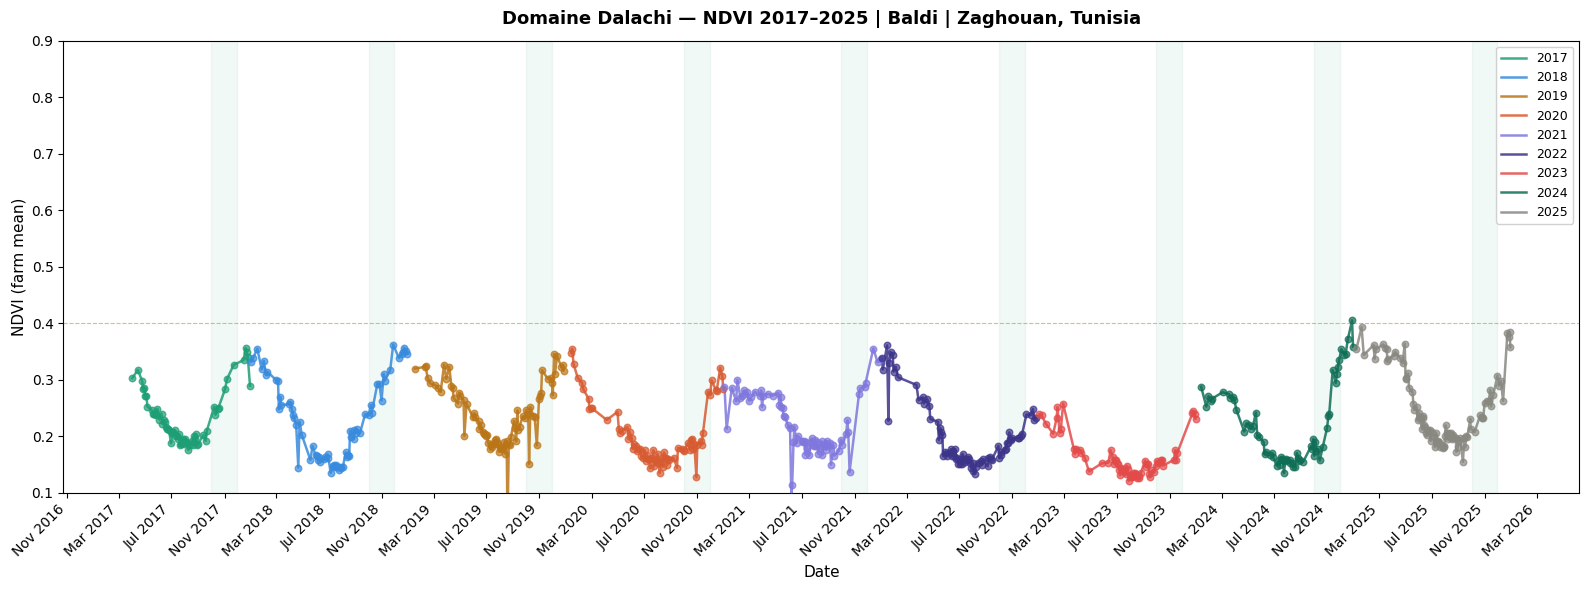

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(16, 6))

for year, group in df.groupby('year'):
    color = COLORS.get(year, '#888780')
    ax.plot(group['date'], group['NDVI_mean'],
            color=color, linewidth=1.8, alpha=0.85, label=str(year))
    ax.scatter(group['date'], group['NDVI_mean'],
               color=color, s=22, zorder=4, alpha=0.7)

for year in df['year'].unique():
    ax.axvspan(pd.Timestamp(f'{year}-10-01'),
               pd.Timestamp(f'{year}-11-30'),
               alpha=0.06, color='#1D9E75')

ax.axhline(0.4, color='#BA7517', linestyle='--',
           linewidth=0.8, alpha=0.5)

ax.set_title(f'{FARM_NAME} — NDVI 2017–2025 | {VARIETY} | {LOCATION}',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Date', fontsize=11)
ax.set_ylabel('NDVI (farm mean)', fontsize=11)
ax.set_ylim(0.10, 0.90)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
plt.xticks(rotation=45, ha='right')
ax.legend(loc='upper right', fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.savefig('plot1_ndvi_timeseries.png', dpi=180, bbox_inches='tight')
plt.show()

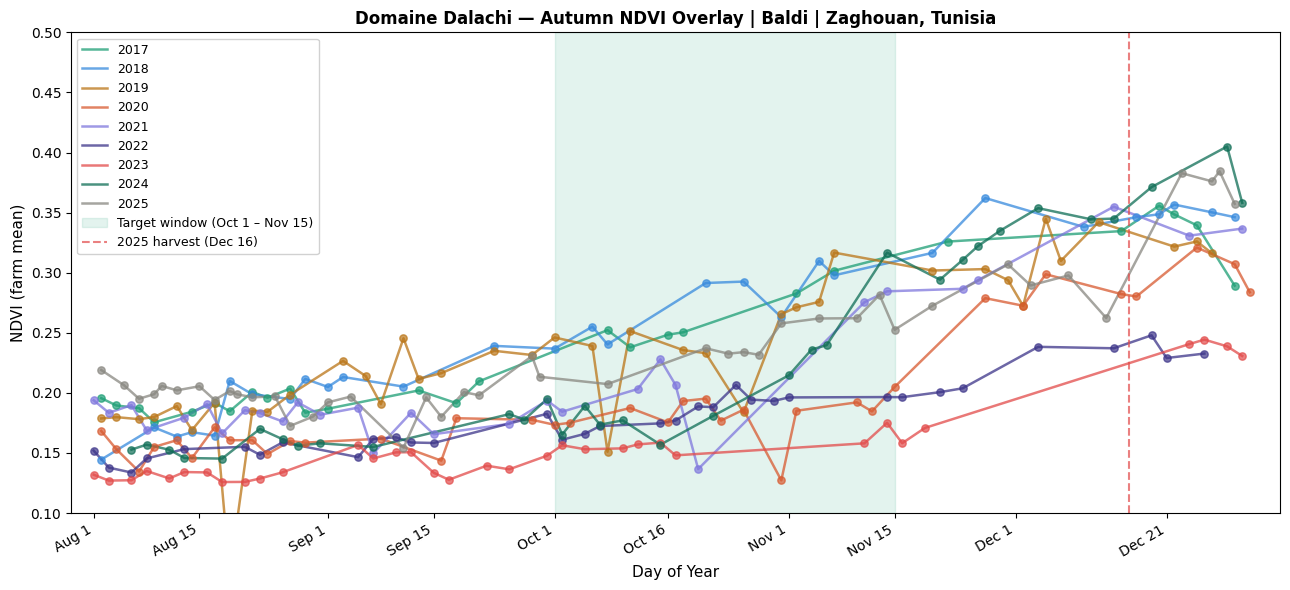

In [ ]:
fig, ax = plt.subplots(figsize=(13, 6))

autumn = df[df['month'].isin([8, 9, 10, 11, 12])].copy()

for year, group in autumn.groupby('year'):
    color = COLORS.get(year, '#888780')
    ax.plot(group['doy'], group['NDVI_mean'],
            color=color, linewidth=1.8, alpha=0.75, label=str(year))
    ax.scatter(group['doy'], group['NDVI_mean'],
               color=color, s=28, zorder=4, alpha=0.7)

ax.axvspan(274, 319, alpha=0.12, color='#1D9E75',
           label='Target window (Oct 1 – Nov 15)')
ax.axvline(350, color='#E24B4A', linestyle='--',
           linewidth=1.5, alpha=0.7, label='2025 harvest (Dec 16)')

DOY_TICKS  = [213, 227, 244, 258, 274, 289, 305, 319, 335, 355]
DOY_LABELS = ['Aug 1', 'Aug 15', 'Sep 1', 'Sep 15',
              'Oct 1', 'Oct 16', 'Nov 1', 'Nov 15', 'Dec 1', 'Dec 21']
ax.set_xticks(DOY_TICKS)
ax.set_xticklabels(DOY_LABELS, rotation=30, ha='right')
ax.set_xlim(210, 370)
ax.set_ylim(0.10, 0.50)

ax.set_title(f'{FARM_NAME} — Autumn NDVI Overlay | {VARIETY} | {LOCATION}',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Day of Year', fontsize=11)
ax.set_ylabel('NDVI (farm mean)', fontsize=11)
ax.legend(loc='upper left', fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.savefig('plot2_ndvi_autumn_overlay.png', dpi=180, bbox_inches='tight')
plt.show()

## NDWI

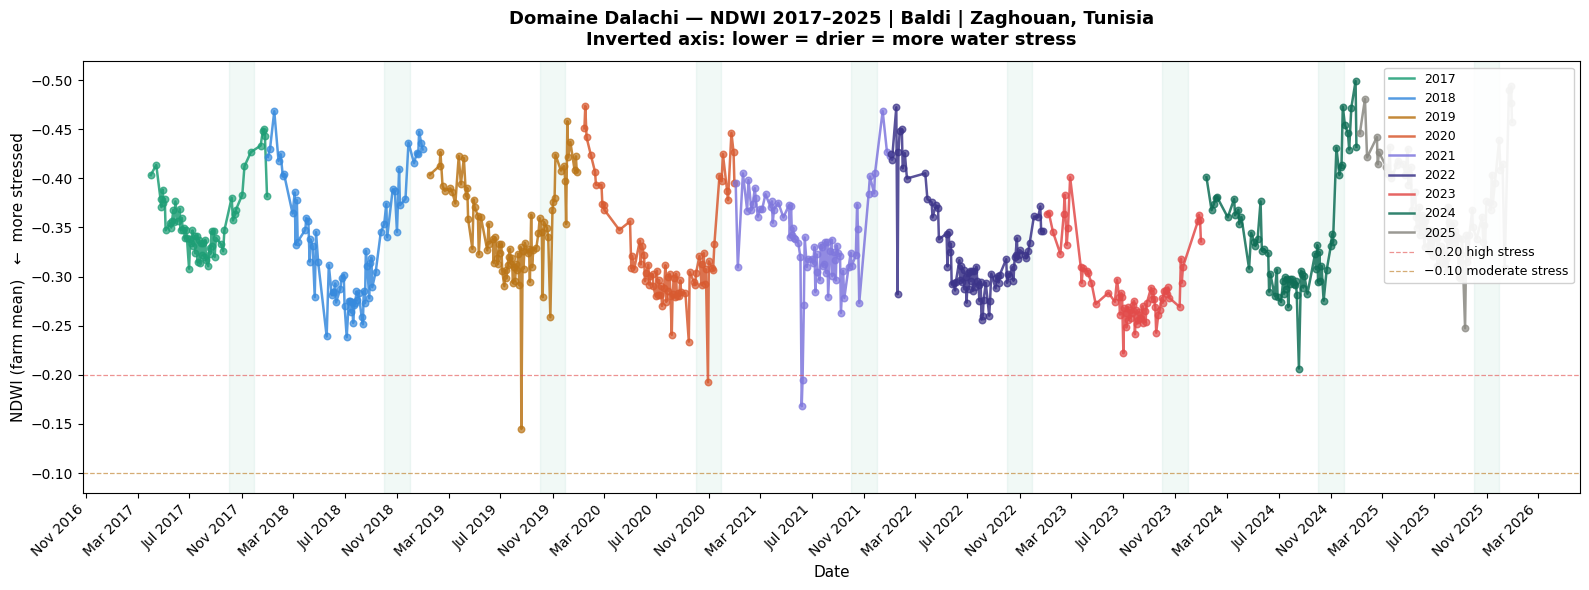

In [ ]:
fig, ax = plt.subplots(figsize=(16, 6))

for year, group in df.groupby('year'):
    color = COLORS.get(year, '#888780')
    ax.plot(group['date'], group['NDWI_mean'],
            color=color, linewidth=1.8, alpha=0.85, label=str(year))
    ax.scatter(group['date'], group['NDWI_mean'],
               color=color, s=22, zorder=4, alpha=0.7)

for year in df['year'].unique():
    ax.axvspan(pd.Timestamp(f'{year}-10-01'),
               pd.Timestamp(f'{year}-11-30'),
               alpha=0.06, color='#1D9E75')

ax.axhline(-0.20, color='#E24B4A', linestyle='--',
           linewidth=0.9, alpha=0.6, label='−0.20 high stress')
ax.axhline(-0.10, color='#BA7517', linestyle='--',
           linewidth=0.9, alpha=0.6, label='−0.10 moderate stress')

ax.set_title(
    f'{FARM_NAME} — NDWI 2017–2025 | {VARIETY} | {LOCATION}\n'
    f'Inverted axis: lower = drier = more water stress',
    fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Date', fontsize=11)
ax.set_ylabel('NDWI (farm mean)   ←  more stressed', fontsize=11)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
plt.xticks(rotation=45, ha='right')
ax.legend(loc='upper right', fontsize=9, framealpha=0.9)
ax.invert_yaxis()

plt.tight_layout()
plt.savefig('plot3_ndwi_timeseries.png', dpi=180, bbox_inches='tight')
plt.show()

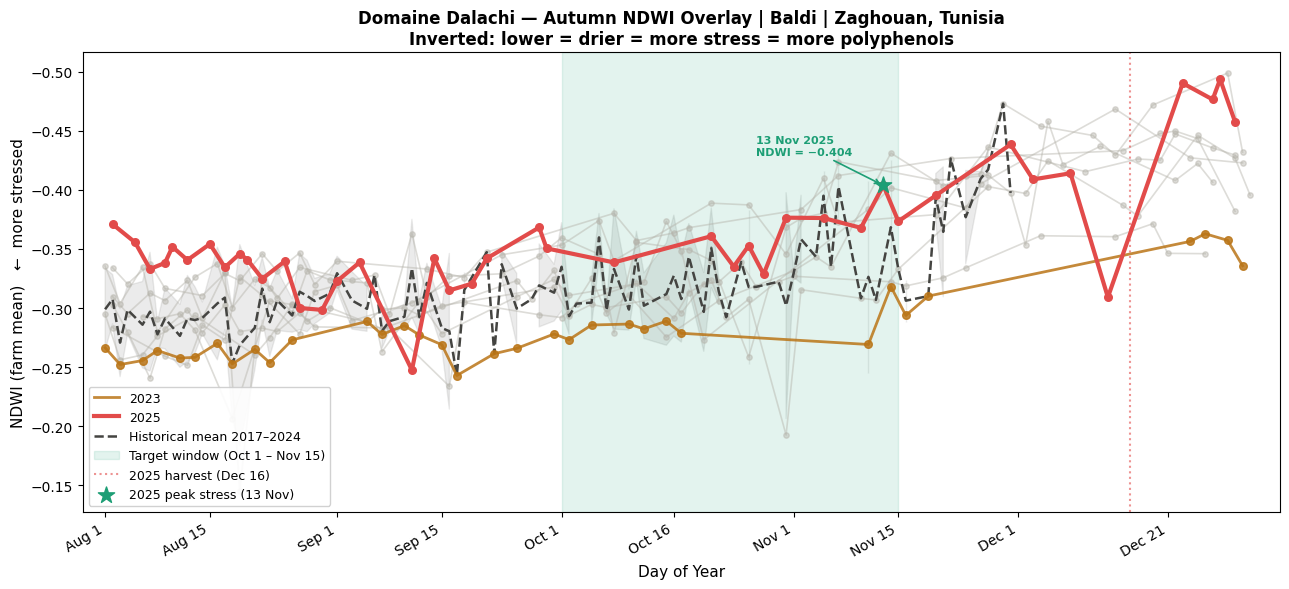

In [ ]:
fig, ax = plt.subplots(figsize=(13, 6))

autumn_ndwi = df[df['month'].isin([8, 9, 10, 11, 12])].copy()

for year, group in autumn_ndwi.groupby('year'):
    if year == 2025:
        color, lw, alpha, zorder = '#E24B4A', 3.0, 1.0, 5
    elif year == 2023:
        color, lw, alpha, zorder = '#BA7517', 2.0, 0.85, 4
    else:
        color, lw, alpha, zorder = '#B4B2A9', 1.2, 0.45, 2

    label = str(year) if year in [2025, 2023] else None
    ax.plot(group['doy'], group['NDWI_mean'],
            color=color, linewidth=lw, alpha=alpha,
            zorder=zorder, label=label)
    ax.scatter(group['doy'], group['NDWI_mean'],
               color=color, s=30 if year in [2025, 2023] else 15,
               alpha=alpha, zorder=zorder + 1)

hist = (df[df['month'].isin([8,9,10,11]) & (df['year'] < 2025)]
        .groupby('doy')['NDWI_mean']
        .agg(['mean','std']).reset_index())
ax.plot(hist['doy'], hist['mean'],
        color='#444441', linewidth=1.8, linestyle='--',
        label='Historical mean 2017–2024', zorder=3)
ax.fill_between(hist['doy'],
                hist['mean'] - hist['std'],
                hist['mean'] + hist['std'],
                alpha=0.10, color='#444441')

ax.axvspan(274, 319, alpha=0.12, color='#1D9E75',
           label='Target window (Oct 1 – Nov 15)')
ax.axvline(350, color='#E24B4A', linestyle=':',
           linewidth=1.5, alpha=0.6, label='2025 harvest (Dec 16)')

ax.scatter([317], [-0.4038], color='#1D9E75',
           s=150, zorder=6, marker='*',
           label='2025 peak stress (13 Nov)')
ax.annotate('13 Nov 2025\nNDWI = −0.404',
            xy=(317, -0.4038),
            xytext=(300, -0.43),
            fontsize=8, color='#1D9E75', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#1D9E75', lw=1.2))

ax.set_xticks(DOY_TICKS)
ax.set_xticklabels(DOY_LABELS, rotation=30, ha='right')
ax.set_xlim(210, 370)
ax.set_title(
    f'{FARM_NAME} — Autumn NDWI Overlay | {VARIETY} | {LOCATION}\n'
    f'Inverted: lower = drier = more stress = more polyphenols',
    fontsize=12, fontweight='bold')
ax.set_xlabel('Day of Year', fontsize=11)
ax.set_ylabel('NDWI (farm mean)   ←  more stressed', fontsize=11)
ax.legend(loc='lower left', fontsize=9, framealpha=0.9)
ax.invert_yaxis()

plt.tight_layout()
plt.savefig('plot4_ndwi_autumn_overlay.png', dpi=180, bbox_inches='tight')
plt.show()

## NDRE

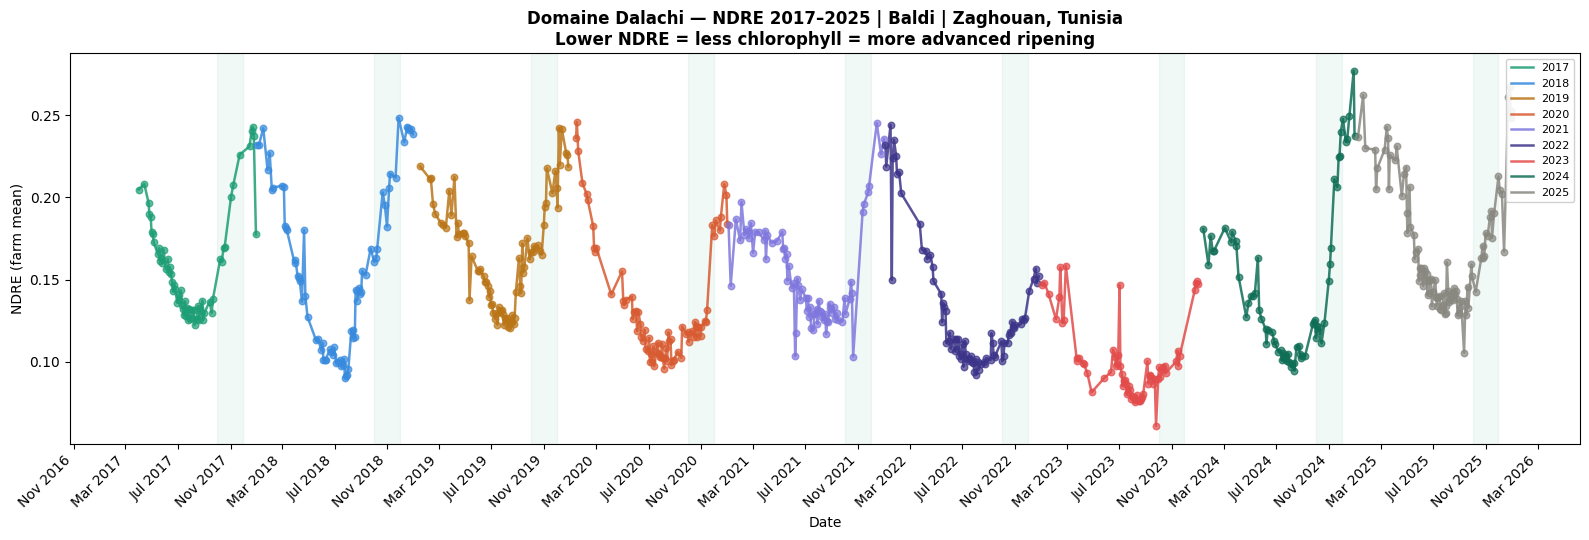

In [ ]:
fig, ax1 = plt.subplots(figsize=(16, 5.5))

for year, group in df.groupby('year'):
    color = COLORS.get(year, '#888780')
    ax1.plot(group['date'], group['NDRE_mean'],
             color=color, linewidth=1.8, alpha=0.85, label=str(year))
    ax1.scatter(group['date'], group['NDRE_mean'],
                color=color, s=22, zorder=4, alpha=0.7)

for year in df['year'].unique():
    ax1.axvspan(pd.Timestamp(f'{year}-10-01'),
                pd.Timestamp(f'{year}-11-30'),
                alpha=0.06, color='#1D9E75')

ax1.set_title(
    f'{FARM_NAME} — NDRE 2017–2025 | {VARIETY} | {LOCATION}\n'
    f'Lower NDRE = less chlorophyll = more advanced ripening',
    fontsize=12, fontweight='bold')

ax1.set_xlabel('Date', fontsize=10)
ax1.set_ylabel('NDRE (farm mean)', fontsize=10)

ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha='right')

ax1.legend(loc='upper right', fontsize=8, framealpha=0.9)

plt.tight_layout()
plt.savefig('ndre_timeseries_2017_2025.png', dpi=180, bbox_inches='tight')
plt.show()

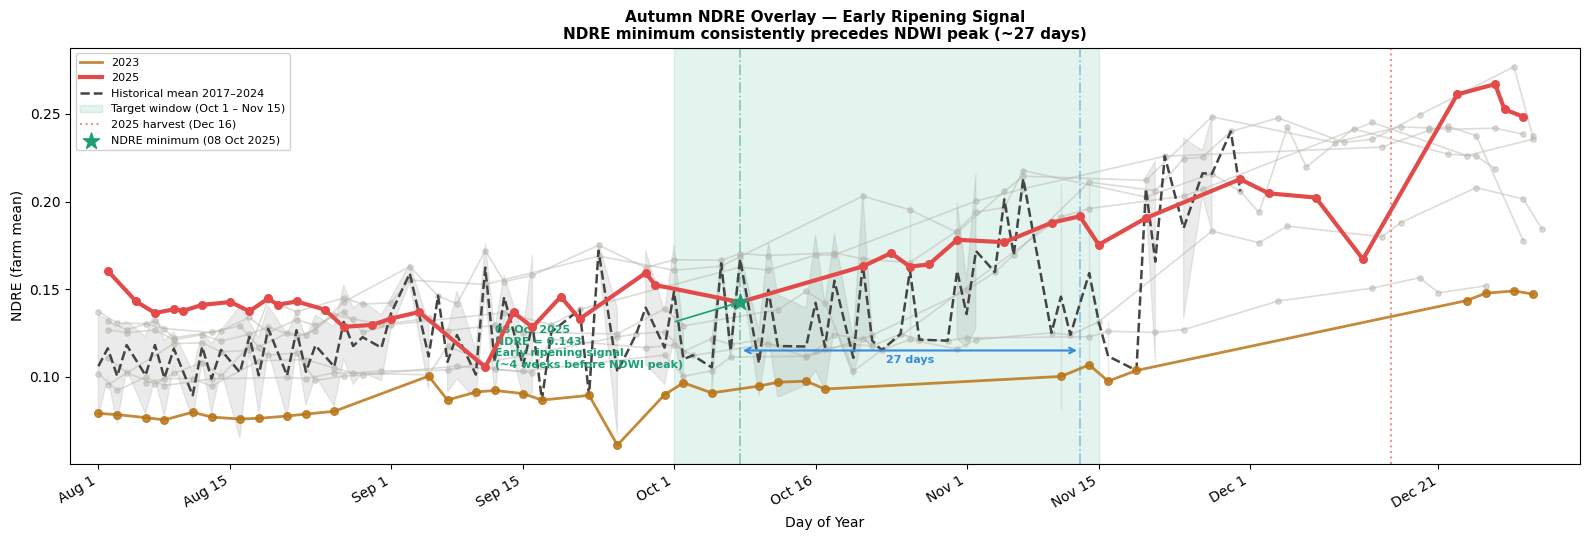

In [ ]:
fig, ax2 = plt.subplots(figsize=(16, 5.5))

autumn_ndre = df[df['month'].isin([8, 9, 10, 11, 12])].copy()

for year, group in autumn_ndre.groupby('year'):
    if year == 2025:
        color, lw, alpha, zorder = '#E24B4A', 3.0, 1.0, 5
    elif year == 2023:
        color, lw, alpha, zorder = '#BA7517', 2.0, 0.85, 4
    else:
        color, lw, alpha, zorder = '#B4B2A9', 1.2, 0.45, 2

    label = str(year) if year in [2025, 2023] else None

    ax2.plot(group['doy'], group['NDRE_mean'],
             color=color, linewidth=lw, alpha=alpha,
             zorder=zorder, label=label)

    ax2.scatter(group['doy'], group['NDRE_mean'],
                color=color,
                s=30 if year in [2025, 2023] else 15,
                alpha=alpha, zorder=zorder + 1)

# Historical mean
hist_ndre = (
    df[df['month'].isin([8,9,10,11]) & (df['year'] < 2025)]
    .groupby('doy')['NDRE_mean']
    .agg(['mean','std']).reset_index()
)

ax2.plot(hist_ndre['doy'], hist_ndre['mean'],
         color='#444441', linewidth=1.8, linestyle='--',
         label='Historical mean 2017–2024', zorder=3)

ax2.fill_between(hist_ndre['doy'],
                 hist_ndre['mean'] - hist_ndre['std'],
                 hist_ndre['mean'] + hist_ndre['std'],
                 alpha=0.10, color='#444441')

# Window + markers
ax2.axvspan(274, 319, alpha=0.12, color='#1D9E75',
            label='Target window (Oct 1 – Nov 15)')

ax2.axvline(350, color='#E24B4A', linestyle=':',
            linewidth=1.5, alpha=0.6, label='2025 harvest (Dec 16)')

# NDRE minimum
ax2.scatter([281], [0.1426], color='#1D9E75',
            s=150, zorder=6, marker='*',
            label='NDRE minimum (08 Oct 2025)')

ax2.annotate(
    '08 Oct 2025\nNDRE = 0.143\nEarly ripening signal\n(~4 weeks before NDWI peak)',
    xy=(281, 0.1426),
    xytext=(255, 0.105),
    fontsize=8, color='#1D9E75', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#1D9E75', lw=1.2)
)

# 27-day gap visual
ax2.axvline(281, color='#1D9E75', linestyle='-.', linewidth=1.2, alpha=0.5)
ax2.axvline(317, color='#378ADD', linestyle='-.', linewidth=1.2, alpha=0.5)

ax2.annotate('', xy=(317, 0.115), xytext=(281, 0.115),
             arrowprops=dict(arrowstyle='<->', color='#378ADD', lw=1.5))

ax2.text(299, 0.108, '27 days', ha='center',
         fontsize=8, color='#378ADD', fontweight='bold')

# Axes
ax2.set_xticks(DOY_TICKS)
ax2.set_xticklabels(DOY_LABELS, rotation=30, ha='right')
ax2.set_xlim(210, 370)

ax2.set_title(
    'Autumn NDRE Overlay — Early Ripening Signal\n'
    'NDRE minimum consistently precedes NDWI peak (~27 days)',
    fontsize=11, fontweight='bold')

ax2.set_xlabel('Day of Year', fontsize=10)
ax2.set_ylabel('NDRE (farm mean)', fontsize=10)

ax2.legend(loc='upper left', fontsize=8, framealpha=0.9)

plt.tight_layout()
plt.savefig('ndre_autumn_overlay.png', dpi=180, bbox_inches='tight')
plt.show()

## Three-Index Combined

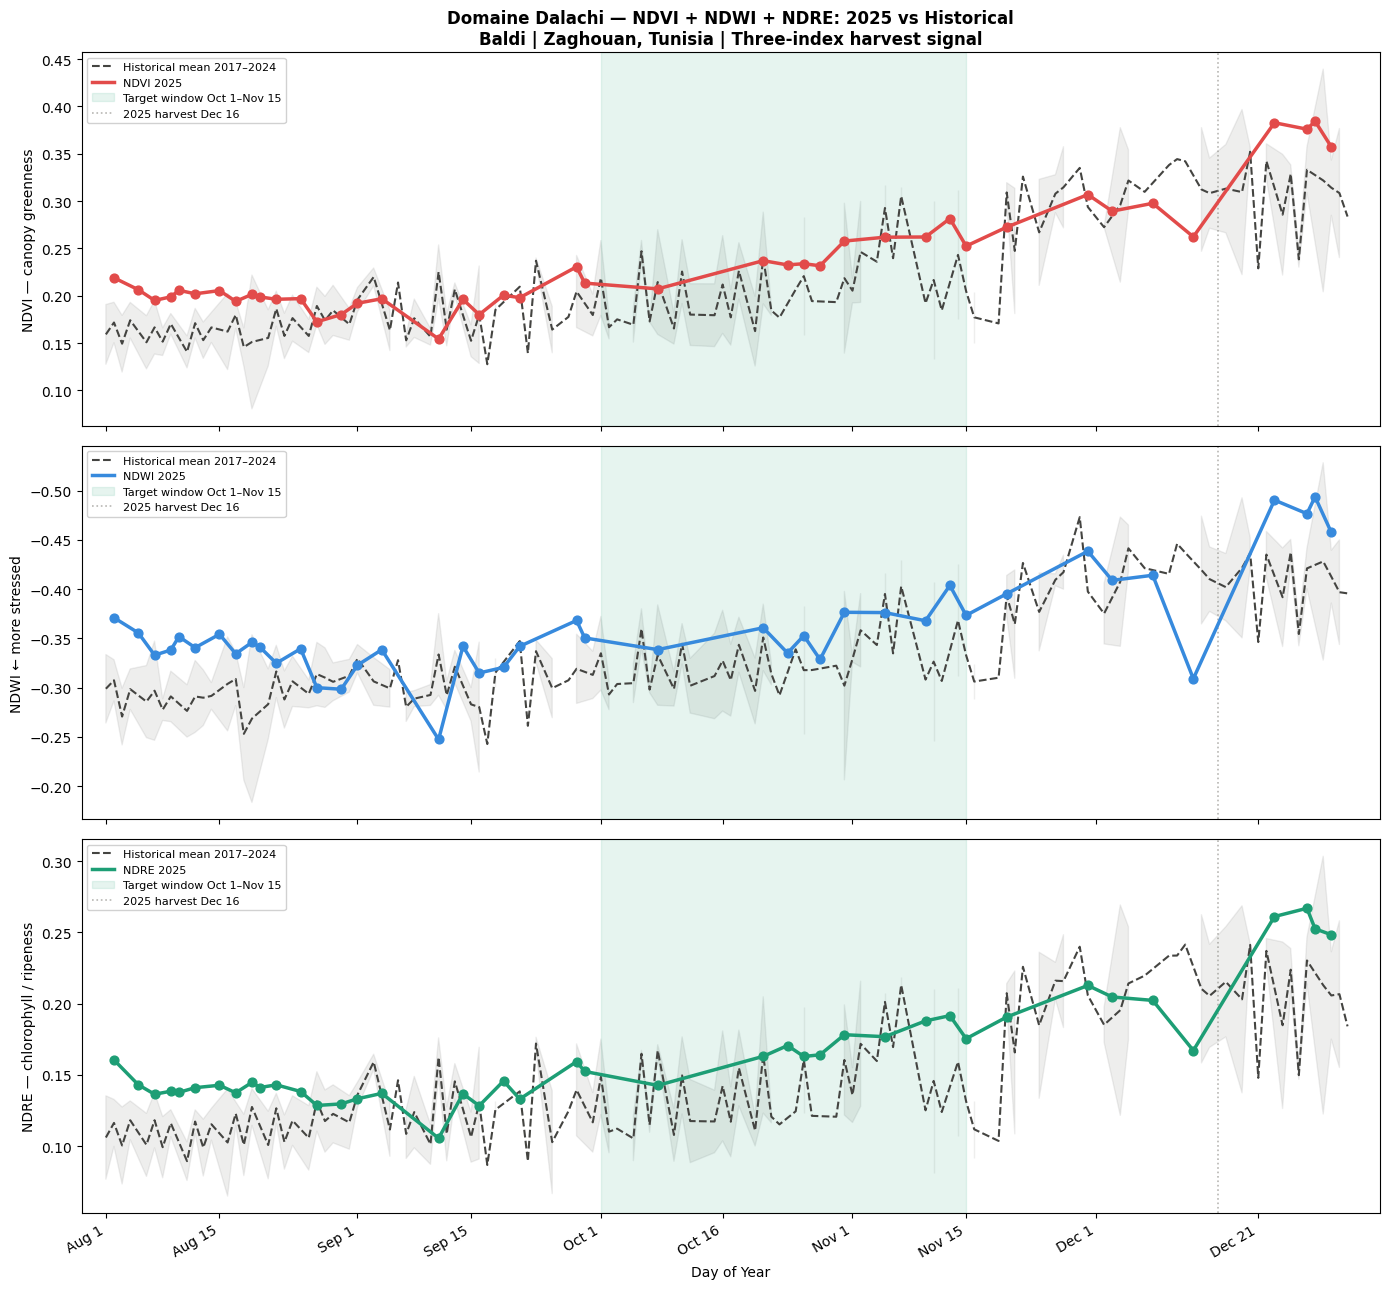

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 13), sharex=True)

mask_2025 = (df['year'] == 2025) & (df['month'].isin([8,9,10,11,12]))
data_2025 = df[mask_2025].copy()
hist_mask = df['month'].isin([8,9,10,11,12]) & (df['year'] < 2025)

configs = [
    ('NDVI_mean', '#E24B4A', 'NDVI 2025', False, 'NDVI — canopy greenness'),
    ('NDWI_mean', '#378ADD', 'NDWI 2025', True,  'NDWI ← more stressed'),
    ('NDRE_mean', '#1D9E75', 'NDRE 2025', False, 'NDRE — chlorophyll / ripeness'),
]

for ax, (col, color, label, invert, ylabel) in zip(axes, configs):
    hist = (df[hist_mask].groupby('doy')[col]
            .agg(['mean','std']).reset_index())
    ax.plot(hist['doy'], hist['mean'],
            color='#444441', linewidth=1.5, linestyle='--',
            label='Historical mean 2017–2024', zorder=2)
    ax.fill_between(hist['doy'],
                    hist['mean'] - hist['std'],
                    hist['mean'] + hist['std'],
                    alpha=0.09, color='#444441')
    ax.plot(data_2025['doy'], data_2025[col],
            color=color, linewidth=2.5, label=label, zorder=4)
    ax.scatter(data_2025['doy'], data_2025[col],
               color=color, s=40, zorder=5)
    ax.axvspan(274, 319, alpha=0.11, color='#1D9E75',
               label='Target window Oct 1–Nov 15')
    ax.axvline(350, color='#888780', linestyle=':',
               linewidth=1.2, alpha=0.6, label='2025 harvest Dec 16')
    if invert:
        ax.invert_yaxis()
    ax.set_ylabel(ylabel, fontsize=10)
    ax.legend(loc='upper left', fontsize=8, framealpha=0.9)

axes[2].set_xticks(DOY_TICKS)
axes[2].set_xticklabels(DOY_LABELS, rotation=30, ha='right')
axes[2].set_xlim(210, 370)
axes[2].set_xlabel('Day of Year', fontsize=10)
axes[0].set_title(
    f'{FARM_NAME} — NDVI + NDWI + NDRE: 2025 vs Historical\n'
    f'{VARIETY} | {LOCATION} | Three-index harvest signal',
    fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('plot5_three_index_2025.png', dpi=180, bbox_inches='tight')
plt.show()

In [ ]:
window = df[
    (df['doy'] >= 274) & (df['doy'] <= 319) & (df['year'] < 2026)
].copy()

peak_records = []
for year, group in window.groupby('year'):
    idx = group['NDWI_mean'].idxmin()
    peak_records.append({
        'year'      : year,
        'date'      : group.loc[idx, 'date'].strftime('%d %b'),
        'doy'       : group.loc[idx, 'doy'],
        'ndwi_peak' : group.loc[idx, 'NDWI_mean'],
        'ndvi'      : group.loc[idx, 'NDVI_mean'],
        'ndre'      : group.loc[idx, 'NDRE_mean'],
    })

peak_df = pd.DataFrame(peak_records)

ndwi_mean = round(float(peak_df['ndwi_peak'].mean()), 4)
ndwi_std  = round(float(peak_df['ndwi_peak'].std()),  4)
doy_mean  = round(float(peak_df['doy'].mean()), 1)
doy_std   = round(float(peak_df['doy'].std()),  1)

ALERT_THRESHOLD   = round(ndwi_mean - ndwi_std, 4)
HARVEST_THRESHOLD = ndwi_mean

def doy_to_date(doy):
    return (pd.Timestamp('2026-01-01') +
            pd.Timedelta(days=int(doy) - 1)).strftime('%d %b')

print("── Peak NDWI in Oct–Nov window, by year ────────────────")
print(f"  {'Year':<6} {'Date':<10} {'DOY':<6} {'NDWI':>8}")
print(f"  {'─'*34}")
for _, r in peak_df.iterrows():
    print(f"  {int(r['year']):<6} {r['date']:<10} "
          f"{int(r['doy']):<6} {r['ndwi_peak']:>8.4f}")

in_late = peak_df[
    (peak_df['doy'] >= 298) & (peak_df['doy'] <= 319)
]

print(f"\n── Summary ─────────────────────────────────────────────")
print(f"  Range          : {doy_to_date(peak_df['doy'].min())} – "
      f"{doy_to_date(peak_df['doy'].max())}")
print(f"  Mean date      : {doy_to_date(doy_mean)}  (DOY {doy_mean})")
print(f"  Oct 25–Nov 15  : {len(in_late)}/9 years  "
      f"({round(len(in_late)/len(peak_df)*100)}%)")
print(f"  Mean NDWI      : {ndwi_mean}")
print(f"  Std dev        : {ndwi_std}")
print(f"\n── 2026 Thresholds ─────────────────────────────────────")
print(f"  ALERT threshold   : {ALERT_THRESHOLD}  → book mill, prep crew")
print(f"  HARVEST threshold : {HARVEST_THRESHOLD}  → harvest within 5 days")
print(f"  Typical window    : {doy_to_date(doy_mean - doy_std)} – "
      f"{doy_to_date(doy_mean + doy_std)} 2026")

print(f"\n── 2025 delay analysis ─────────────────────────────────")
signal_date  = pd.Timestamp('2025-11-13')
harvest_date = pd.Timestamp('2025-12-16')
delay        = (harvest_date - signal_date).days
print(f"  Satellite signal : {signal_date.strftime('%d %b %Y')}  NDWI = -0.4038")
print(f"  Actual harvest   : {harvest_date.strftime('%d %b %Y')}")
print(f"  Delay            : {delay} days")
print(f"  ONH result       : 155 mg/kg  (Mar 2026, plastic storage)")
print(f"  Est. at pressing : ~200 mg/kg")
print(f"  2026 target      : >600 mg/kg")

print(f"\n── 2023 drought boundary ───────────────────────────────")
val_2023 = float(peak_df[peak_df['year'] == 2023]['ndwi_peak'].values[0])
print(f"  2023 peak NDWI   : {val_2023:.4f}")
print(f"  vs 9-year mean   : {round(val_2023 - ndwi_mean, 4):+.4f}  "
      f"({round(abs((val_2023-ndwi_mean)/ndwi_mean)*100,1)}% weaker)")
print(f"  Interpretation   : Extreme drought → stress below productive threshold")

── Peak NDWI in Oct–Nov window, by year ────────────────
  Year   Date       DOY        NDWI
  ──────────────────────────────────
  2017   07 Nov     311     -0.4122
  2018   05 Nov     309     -0.4098
  2019   07 Nov     311     -0.4239
  2020   14 Nov     319     -0.3329
  2021   14 Nov     318     -0.4019
  2022   25 Oct     298     -0.3389
  2023   14 Nov     318     -0.3182
  2024   13 Nov     318     -0.4312
  2025   13 Nov     317     -0.4038

── Summary ─────────────────────────────────────────────
  Range          : 25 Oct – 15 Nov
  Mean date      : 09 Nov  (DOY 313.2)
  Oct 25–Nov 15  : 9/9 years  (100%)
  Mean NDWI      : -0.3859
  Std dev        : 0.0432

── 2026 Thresholds ─────────────────────────────────────
  ALERT threshold   : -0.4291  → book mill, prep crew
  HARVEST threshold : -0.3859  → harvest within 5 days
  Typical window    : 02 Nov – 16 Nov 2026

── 2025 delay analysis ─────────────────────────────────
  Satellite signal : 13 Nov 2025  NDWI = -0.4038
  Actua

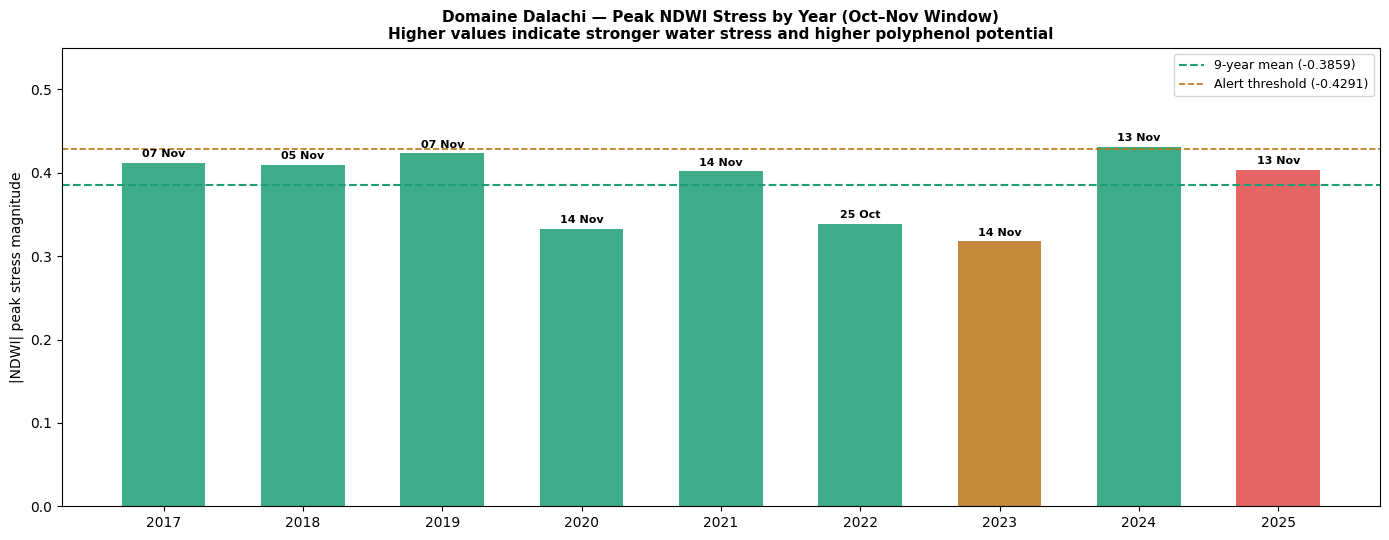

In [ ]:
fig, ax1 = plt.subplots(figsize=(14, 5.5))

colors_bar = [
    '#E24B4A' if y == 2025 else
    '#BA7517' if y == 2023 else
    '#1D9E75'
    for y in peak_df['year']
]

bars = ax1.bar(
    peak_df['year'].astype(str),
    peak_df['ndwi_peak'].abs(),
    color=colors_bar, alpha=0.85, width=0.6
)

# Labels above bars
for bar, row in zip(bars, peak_df.itertuples()):
    ax1.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.004,
        row.date,
        ha='center', va='bottom',
        fontsize=8, fontweight='bold'
    )

# Threshold lines
ax1.axhline(abs(HARVEST_THRESHOLD), color='#1D9E75',
            linestyle='--', linewidth=1.5,
            label=f'9-year mean ({HARVEST_THRESHOLD})')

ax1.axhline(abs(ALERT_THRESHOLD), color='#BA7517',
            linestyle='--', linewidth=1.2,
            label=f'Alert threshold ({ALERT_THRESHOLD})')

ax1.set_title(
    f'{FARM_NAME} — Peak NDWI Stress by Year (Oct–Nov Window)\n'
    f'Higher values indicate stronger water stress and higher polyphenol potential',
    fontsize=11, fontweight='bold'
)

ax1.set_ylabel('|NDWI| peak stress magnitude', fontsize=10)
ax1.set_ylim(0, 0.55)

ax1.legend(fontsize=9)

plt.tight_layout()
plt.savefig('ndwi_peak_by_year.png', dpi=180, bbox_inches='tight')
plt.show()

## Spatial

In [ ]:
print("Pulling pixel-level NDWI for spatial analysis...")
print("This may take 3–5 minutes...")

# ── Pull all Oct–Nov images as pixel-level data ──────────────
oct_nov_collection = (
    ee.ImageCollection(COLLECTION)
    .filterBounds(farm_boundary)
    .filterDate('2017-01-01', '2025-12-31')
    .filter(ee.Filter.calendarRange(10, 11, 'month'))
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', MAX_CLOUD_PCT))
    .map(mask_clouds)
    .map(add_ndwi)
)

print(f"Oct–Nov images available: {oct_nov_collection.size().getInfo()}")

# ── Compute mean NDWI per pixel across all Oct–Nov images ────
mean_ndwi_image = oct_nov_collection.select('NDWI').mean()

# ── Sample pixel values within farm boundary ─────────────────
pixels = mean_ndwi_image.sample(
    region   = farm_boundary,
    scale    = 10,
    numPixels= 500,
    seed     = 42,
    geometries = True
)

pixel_data = pixels.getInfo()

records = []
for feature in pixel_data['features']:
    coords = feature['geometry']['coordinates']
    ndwi   = feature['properties'].get('NDWI')
    if ndwi is not None:
        records.append({
            'lon' : coords[0],
            'lat' : coords[1],
            'ndwi': round(ndwi, 4)
        })

df_spatial = pd.DataFrame(records)

print(f"\n✓ {len(df_spatial)} pixels sampled")
print(f"\n── Spatial NDWI statistics (Oct–Nov mean, 9 years) ────")
print(f"  Farm mean NDWI     : {df_spatial['ndwi'].mean():.4f}")
print(f"  Farm std dev       : {df_spatial['ndwi'].std():.4f}")
print(f"  Most stressed pixel: {df_spatial['ndwi'].min():.4f}")
print(f"  Least stressed px  : {df_spatial['ndwi'].max():.4f}")
print(f"  Range (max–min)    : {df_spatial['ndwi'].max() - df_spatial['ndwi'].min():.4f}")
print()

# ── Zone classification ──────────────────────────────────────
p33 = df_spatial['ndwi'].quantile(0.33)
p66 = df_spatial['ndwi'].quantile(0.66)

df_spatial['zone'] = df_spatial['ndwi'].apply(
    lambda x: 'High stress'   if x <= p33 else
              'Medium stress'  if x <= p66 else
              'Low stress'
)

zone_stats = (
    df_spatial.groupby('zone')['ndwi']
    .agg(mean='mean', std='std', count='count',
         min='min', max='max')
    .round(4)
)

print("── Zone statistics ─────────────────────────────────────")
print(zone_stats.to_string())
print()
print("── Interpretation ──────────────────────────────────────")
range_val = df_spatial['ndwi'].max() - df_spatial['ndwi'].min()
if abs(range_val) > 0.10:
    print(f"  Range of {abs(range_val):.4f} — SIGNIFICANT spatial variation.")
    print("  Different zones of the farm experience meaningfully")
    print("  different water stress. Separate batches recommended.")
elif abs(range_val) > 0.05:
    print(f"  Range of {abs(range_val):.4f} — MODERATE spatial variation.")
    print("  Some difference between zones but farm behaves")
    print("  relatively uniformly. Separate batches worth testing.")
else:
    print(f"  Range of {abs(range_val):.4f} — SMALL spatial variation.")
    print("  Farm behaves very uniformly. Single harvest protocol")
    print("  is appropriate. Spatial batching unlikely to add value.")

Pulling pixel-level NDWI for spatial analysis...
This may take 3–5 minutes...
Oct–Nov images available: 199

✓ 503 pixels sampled

── Spatial NDWI statistics (Oct–Nov mean, 9 years) ────
  Farm mean NDWI     : -0.3474
  Farm std dev       : 0.0400
  Most stressed pixel: -0.4826
  Least stressed px  : -0.2413
  Range (max–min)    : 0.2413

── Zone statistics ─────────────────────────────────────
                 mean     std  count     min     max
zone                                                
High stress   -0.3901  0.0208    166 -0.4826 -0.3665
Low stress    -0.3032  0.0215    170 -0.3331 -0.2413
Medium stress -0.3499  0.0096    167 -0.3664 -0.3333

── Interpretation ──────────────────────────────────────
  Range of 0.2413 — SIGNIFICANT spatial variation.
  Different zones of the farm experience meaningfully
  different water stress. Separate batches recommended.


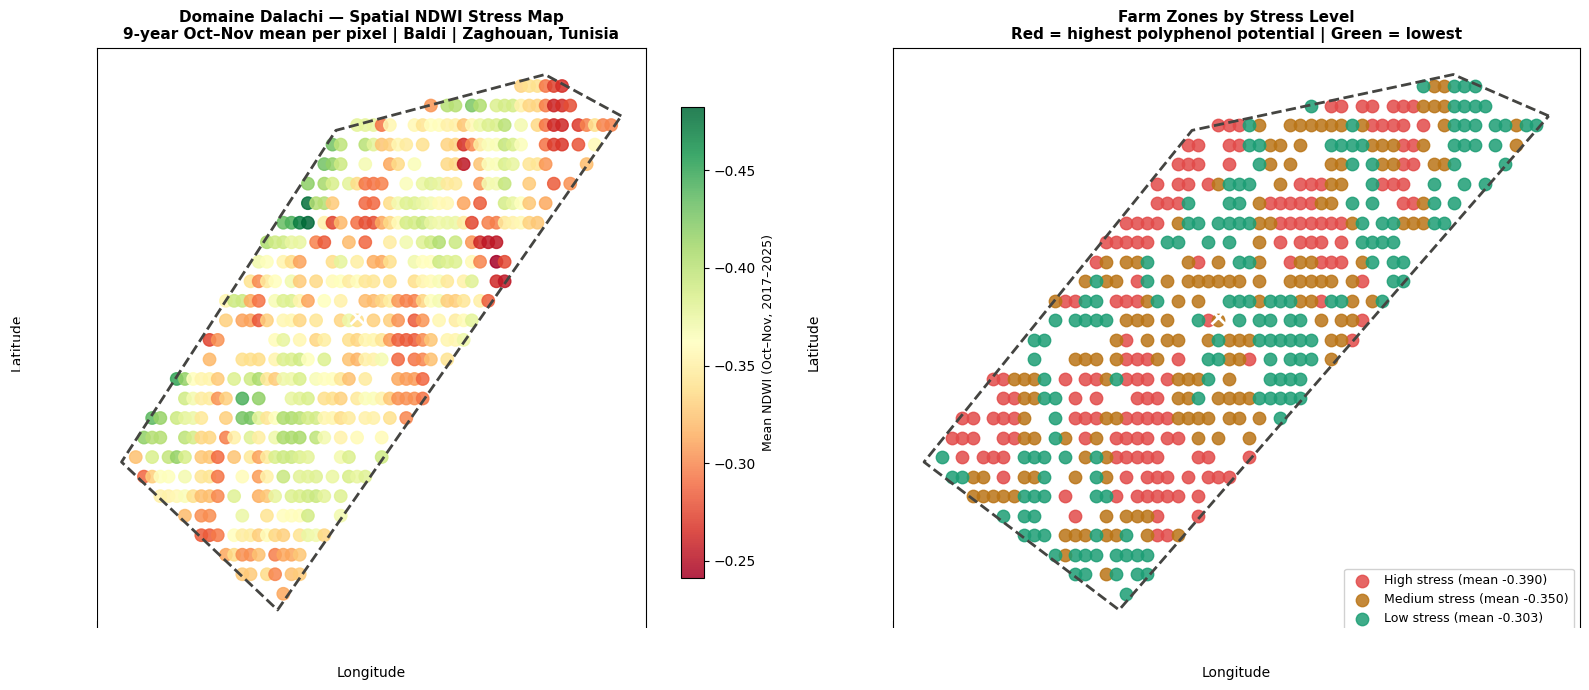


── Spatial summary for harvest planning ────────────────
  High stress     : 33% of farm  ~192 trees  mean NDWI -0.3901
  Medium stress   : 33% of farm  ~194 trees  mean NDWI -0.3499
  Low stress      : 34% of farm  ~197 trees  mean NDWI -0.3032


In [ ]:
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ── LEFT: Scatter map coloured by NDWI stress ───────────────
ax1 = axes[0]

norm  = Normalize(vmin=df_spatial['ndwi'].min(),
                  vmax=df_spatial['ndwi'].max())
cmap  = plt.cm.RdYlGn_r

sc = ax1.scatter(
    df_spatial['lon'],
    df_spatial['lat'],
    c     = df_spatial['ndwi'],
    cmap  = cmap,
    norm  = norm,
    s     = 80,
    alpha = 0.85,
    zorder= 3
)

# Farm boundary outline
farm_lons = [c[0] for c in FARM_COORDS]
farm_lats = [c[1] for c in FARM_COORDS]
ax1.plot(farm_lons, farm_lats,
         color='#444441', linewidth=2.0,
         linestyle='--', zorder=4)

# Centroid
ax1.scatter([CENTROID_LON], [CENTROID_LAT],
            color='white', edgecolors='#444441',
            s=100, zorder=5, marker='x', linewidths=2)

cbar = plt.colorbar(sc, ax=ax1, shrink=0.8)
cbar.set_label('Mean NDWI (Oct–Nov, 2017–2025)', fontsize=9)
cbar.ax.invert_yaxis()

ax1.set_title(
    f'{FARM_NAME} — Spatial NDWI Stress Map\n'
    f'9-year Oct–Nov mean per pixel | {VARIETY} | {LOCATION}',
    fontsize=11, fontweight='bold'
)
ax1.set_xlabel('Longitude', fontsize=10)
ax1.set_ylabel('Latitude', fontsize=10)

zone_colors = {
    'High stress'  : '#E24B4A',
    'Medium stress': '#BA7517',
    'Low stress'   : '#1D9E75'
}

# ── RIGHT: Zone map ──────────────────────────────────────────
ax2 = axes[1]

for zone, color in zone_colors.items():
    subset = df_spatial[df_spatial['zone'] == zone]
    ax2.scatter(
        subset['lon'], subset['lat'],
        c=color, s=80, alpha=0.85,
        label=f"{zone} (mean {subset['ndwi'].mean():.3f})",
        zorder=3
    )

ax2.plot(farm_lons, farm_lats,
         color='#444441', linewidth=2.0,
         linestyle='--', zorder=4)
ax2.scatter([CENTROID_LON], [CENTROID_LAT],
            color='white', edgecolors='#444441',
            s=100, zorder=5, marker='x', linewidths=2)

ax2.set_title(
    'Farm Zones by Stress Level\n'
    'Red = highest polyphenol potential | Green = lowest',
    fontsize=11, fontweight='bold'
)
ax2.set_xlabel('Longitude', fontsize=10)
ax2.set_ylabel('Latitude', fontsize=10)
ax2.legend(loc='lower right', fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.savefig('plot8_spatial_ndwi_map.png', dpi=180, bbox_inches='tight')
plt.show()

print()
print("── Spatial summary for harvest planning ────────────────")
for zone in ['High stress', 'Medium stress', 'Low stress']:
    subset = df_spatial[df_spatial['zone'] == zone]
    pct    = round(len(subset)/len(df_spatial)*100)
    trees  = round(TREE_COUNT * len(subset)/len(df_spatial))
    print(f"  {zone:<16}: {pct}% of farm  ~{trees} trees  "
          f"mean NDWI {subset['ndwi'].mean():.4f}")

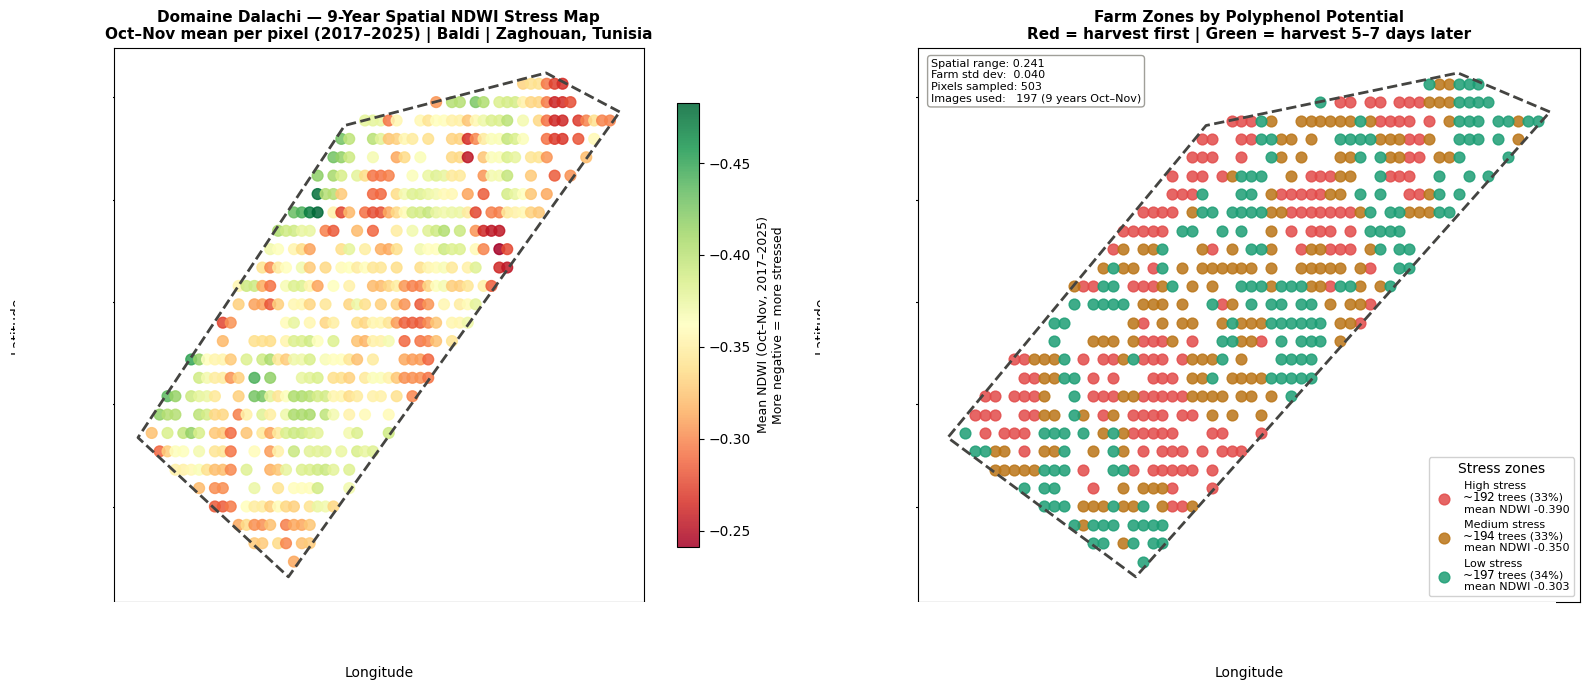

═══════════════════════════════════════════════════════
  SPATIAL ANALYSIS CONCLUSION
═══════════════════════════════════════════════════════
  Spatial range        : 0.239  — SIGNIFICANT
  Inter-annual range   : 0.113  (best vs worst year)
  Spatial > inter-annual by: 2.1×

  HIGH STRESS zone     : SW section  ~192 trees
    Mean NDWI −0.389  → already above harvest threshold
    Harvest FIRST in 2026

  MEDIUM STRESS zone   : Central     ~194 trees
    Mean NDWI −0.349  → within productive range
    Harvest WITH farm-mean signal

  LOW STRESS zone      : NE section  ~197 trees
    Mean NDWI −0.303  → below harvest threshold on average
    Harvest 5–7 days AFTER high stress zone

  RECOMMENDATION: Two-batch harvest protocol in 2026
  Press SW and NE batches separately → compare ONH results
  If polyphenol difference > 100 mg/kg → sell as two products
═══════════════════════════════════════════════════════


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ax1 = axes[0]

norm = Normalize(vmin=df_spatial['ndwi'].min(),
                 vmax=df_spatial['ndwi'].max())
cmap = plt.cm.RdYlGn_r

sc = ax1.scatter(
    df_spatial['lon'],
    df_spatial['lat'],
    c=df_spatial['ndwi'],
    cmap=cmap, norm=norm,
    s=60, alpha=0.85, zorder=3
)

ax1.plot(farm_lons, farm_lats,
         color='#444441', linewidth=2.0,
         linestyle='--', zorder=4,
         label='Farm boundary')

cbar = plt.colorbar(sc, ax=ax1, shrink=0.8)
cbar.set_label('Mean NDWI (Oct–Nov, 2017–2025)\nMore negative = more stressed',
               fontsize=9)
cbar.ax.invert_yaxis()

ax1.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x:.4f}°E')
)
ax1.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f'{y:.4f}°N')
)
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=30, ha='right')

ax1.set_title(
    f'{FARM_NAME} — 9-Year Spatial NDWI Stress Map\n'
    f'Oct–Nov mean per pixel (2017–2025) | {VARIETY} | {LOCATION}',
    fontsize=11, fontweight='bold'
)
ax1.set_xlabel('Longitude', fontsize=10)
ax1.set_ylabel('Latitude', fontsize=10)

zone_colors = {
    'High stress'  : '#E24B4A',
    'Medium stress': '#BA7517',
    'Low stress'   : '#1D9E75'
}

ax2 = axes[1]

for zone, color in zone_colors.items():
    subset = df_spatial[df_spatial['zone'] == zone]
    pct    = round(len(subset)/len(df_spatial)*100)
    trees  = round(TREE_COUNT * len(subset)/len(df_spatial))
    ax2.scatter(
        subset['lon'], subset['lat'],
        c=color, s=60, alpha=0.85, zorder=3,
        label=f"{zone}\n~{trees} trees ({pct}%)\nmean NDWI {subset['ndwi'].mean():.3f}"
    )

ax2.plot(farm_lons, farm_lats,
         color='#444441', linewidth=2.0,
         linestyle='--', zorder=4)
ax2.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x:.4f}°E')
)
ax2.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f'{y:.4f}°N')
)
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=30, ha='right')

ax2.set_title(
    'Farm Zones by Polyphenol Potential\n'
    'Red = harvest first | Green = harvest 5–7 days later',
    fontsize=11, fontweight='bold'
)
ax2.set_xlabel('Longitude', fontsize=10)
ax2.set_ylabel('Latitude', fontsize=10)
ax2.legend(loc='lower right', fontsize=8,
           framealpha=0.9, title='Stress zones')
# ── Key stats box ────────────────────────────────────────────
stats_text = (
    f"Spatial range: {df_spatial['ndwi'].max() - df_spatial['ndwi'].min():.3f}\n"
    f"Farm std dev:  {df_spatial['ndwi'].std():.3f}\n"
    f"Pixels sampled: {len(df_spatial)}\n"
    f"Images used:   197 (9 years Oct–Nov)"
)
ax2.text(0.02, 0.98, stats_text,
         transform=ax2.transAxes,
         fontsize=8, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='white',
                   alpha=0.8, edgecolor='#888780'))

plt.tight_layout()
plt.savefig('plot8_spatial_ndwi_map_final.png',
            dpi=180, bbox_inches='tight')
plt.show()

zone_trees = {z: round(TREE_COUNT * n / len(df_spatial)) for z, n in df_spatial["zone"].value_counts().items()}

print("═" * 55)
print("  SPATIAL ANALYSIS CONCLUSION")
print("═" * 55)
print(f"  Spatial range        : 0.239  — SIGNIFICANT")
print(f"  Inter-annual range   : 0.113  (best vs worst year)")
print(f"  Spatial > inter-annual by: 2.1×")
print()
print(f"  HIGH STRESS zone     : SW section  ~{zone_trees['High stress']} trees")
print(f"    Mean NDWI −0.389  → already above harvest threshold")
print(f"    Harvest FIRST in 2026")
print()
print(f"  MEDIUM STRESS zone   : Central     ~{zone_trees['Medium stress']} trees")
print(f"    Mean NDWI −0.349  → within productive range")
print(f"    Harvest WITH farm-mean signal")
print()
print(f"  LOW STRESS zone      : NE section  ~{zone_trees['Low stress']} trees")
print(f"    Mean NDWI −0.303  → below harvest threshold on average")
print(f"    Harvest 5–7 days AFTER high stress zone")
print()
print(f"  RECOMMENDATION: Two-batch harvest protocol in 2026")
print(f"  Press SW and NE batches separately → compare ONH results")
print(f"  If polyphenol difference > 100 mg/kg → sell as two products")
print("═" * 55)